In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import numpy as np

# Raw data provided by the user
data_string = """
ESOL +16%(Scaffold vs Random) +65%(Lo-Hi vs Random)
LIPO −18%(Scaffold vs Random) −38%(Lo-Hi vs Random)
FreeSolv +53%(Scaffold vs Random) +201%(Lo-Hi vs Random)
"""

# Seed values for Lo-Hi Split
seeds = {
    'ESOL': [0.5616, 0.5559, 0.5680],
    'FreeSolv': [3.8657, 4.6949, 4.0150],
    'LIPO': [0.7484, 0.7601, 0.6996]
}

# Process the data string
processed_data = []
for line in data_string.strip().split('\n'):
    parts = line.split(' ', 1)
    dataset = parts[0]
    pattern = r'([+−]?\d+)%\(([^)]+)\)'
    matches = re.findall(pattern, parts[1])

    for match in matches:
        percentage = float(match[0].replace('−', '-'))
        comparison = match[1]
        std_error = 0.0

        # If it's the Lo-Hi comparison, calculate the relative error bar
        if 'Lo-Hi' in comparison:
            vals = seeds.get(dataset, [])
            if vals:
                mean_val = np.mean(vals)
                std_val = np.std(vals)
                # Calculate error bar relative to the percentage change
                std_error = (std_val / mean_val) * abs(percentage)

        processed_data.append({
            'Dataset': dataset,
            'Comparison': comparison,
            'Percentage_Change': percentage,
            'std_error': std_error
        })

df_percentage = pd.DataFrame(processed_data)
display(df_percentage)

,Dataset,Comparison,Percentage_Change,std_error
0,ESOL,Scaffold vs Random,16.0,0.000000
1,ESOL,Lo-Hi vs Random,65.0,0.571818
2,LIPO,Scaffold vs Random,-18.0,0.000000
3,LIPO,Lo-Hi vs Random,-38.0,1.352724
4,FreeSolv,Scaffold vs Random,53.0,0.000000
5,FreeSolv,Lo-Hi vs Random,201.0,17.304327


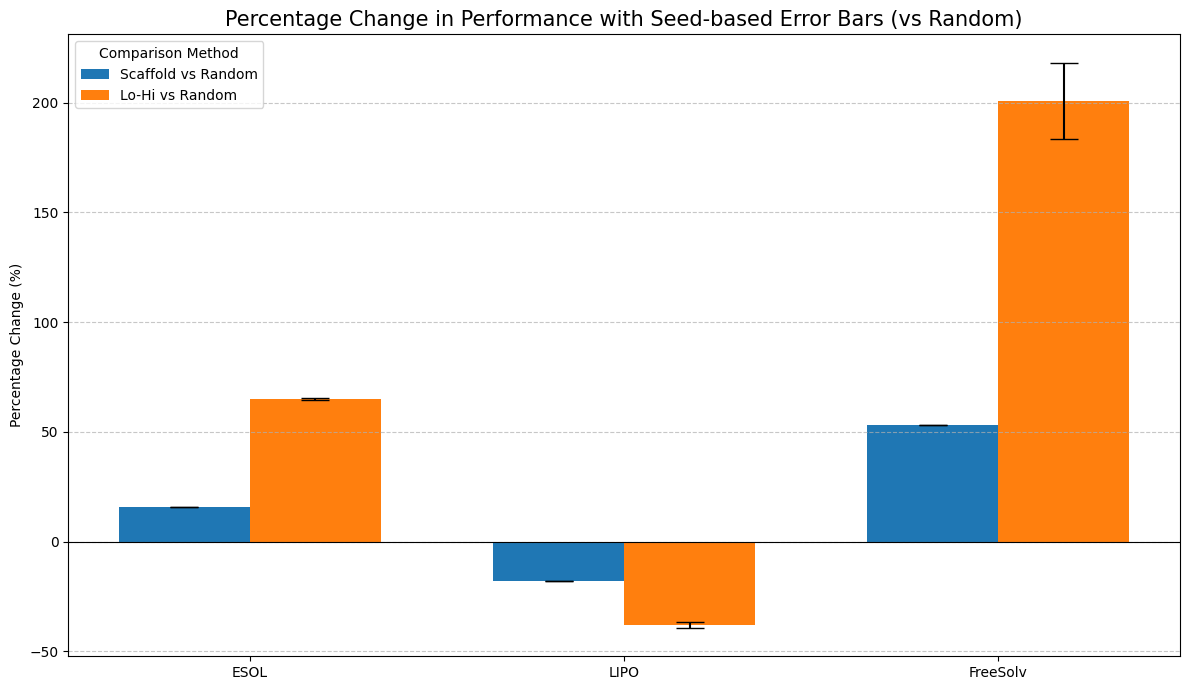

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create the grouped bar chart with error bars
datasets = df_percentage['Dataset'].unique()
comparisons = df_percentage['Comparison'].unique()

x = np.arange(len(datasets))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

for i, comp in enumerate(comparisons):
    subset = df_percentage[df_percentage['Comparison'] == comp]
    # Calculate positions for grouped bars
    pos = x + i*width - width/2
    # Increased capsize and set error bar color to black
    ax.bar(pos, subset['Percentage_Change'], width, label=comp, yerr=subset['std_error'], capsize=10, ecolor='black')

ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Percentage Change in Performance with Seed-based Error Bars (vs Random)', fontsize=15)
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel('Percentage Change (%)')
ax.legend(title='Comparison Method')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()